In [2]:
import pandas as pd

df = pd.read_excel("hospital_synthetic_dataset.xlsx")
print(df.shape)
df.head()

(500, 11)


,age,sex,blood_pressure,cholesterol,bmi,smoker,diabetes,physical_activity,family_history,stress_level,heart_disease
0,68,Male,105,191,38.0,Yes,Yes,0,No,2,0
1,58,Female,97,249,22.0,Yes,Yes,0,No,4,0
2,44,Female,93,190,23.2,No,Yes,0,No,8,0
3,72,Male,93,183,39.4,No,No,3,Yes,1,0
4,37,Female,145,166,22.0,No,Yes,4,Yes,1,0


In [3]:
print(df.info())
print(df.describe())
print(df["heart_disease"].value_counts())
print("Missing values:", df.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   sex                500 non-null    object 
 2   blood_pressure     500 non-null    int64  
 3   cholesterol        500 non-null    int64  
 4   bmi                500 non-null    float64
 5   smoker             500 non-null    object 
 6   diabetes           500 non-null    object 
 7   physical_activity  500 non-null    int64  
 8   family_history     500 non-null    object 
 9   stress_level       500 non-null    int64  
 10  heart_disease      500 non-null    int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 43.1+ KB
None
              age  blood_pressure  cholesterol         bmi  physical_activity  \
count  500.000000      500.000000    500.00000  500.000000         500.000000   
mean    54.864000      132.874000    221.

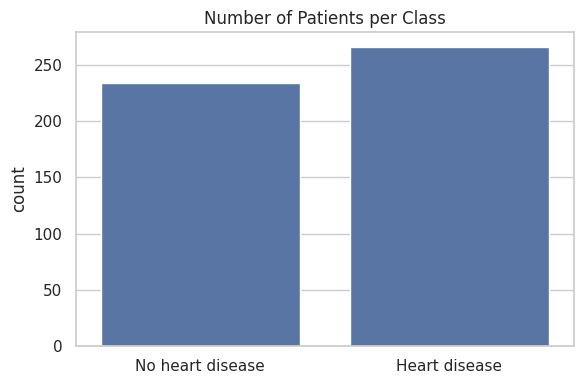

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="heart_disease")
plt.xticks([0, 1], ["No heart disease", "Heart disease"])
plt.xlabel("")
plt.title("Number of Patients per Class")
plt.tight_layout()
plt.savefig("images/class_distribution.png", dpi=300)
plt.show()

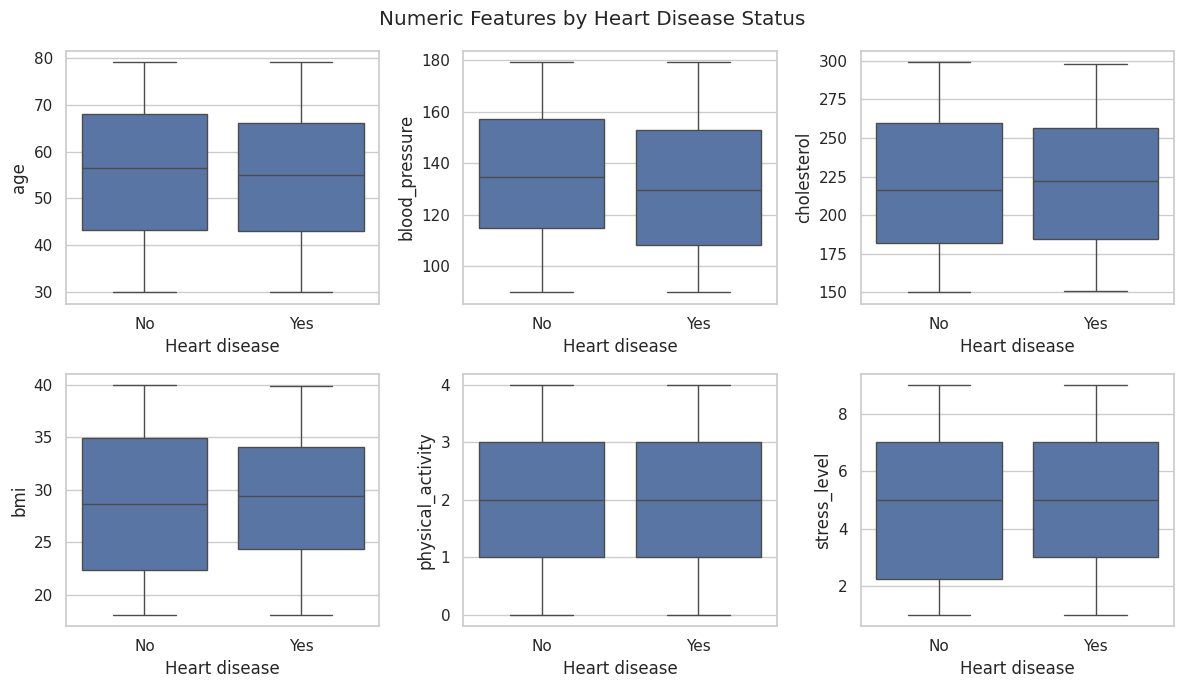

In [5]:
numeric = ["age", "blood_pressure", "cholesterol", "bmi", "physical_activity", "stress_level"]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), numeric):
    sns.boxplot(data=df, x="heart_disease", y=col, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No", "Yes"])
    ax.set_xlabel("Heart disease")
plt.suptitle("Numeric Features by Heart Disease Status")
plt.tight_layout()
plt.savefig("images/numeric_boxplots.png", dpi=300)
plt.show()

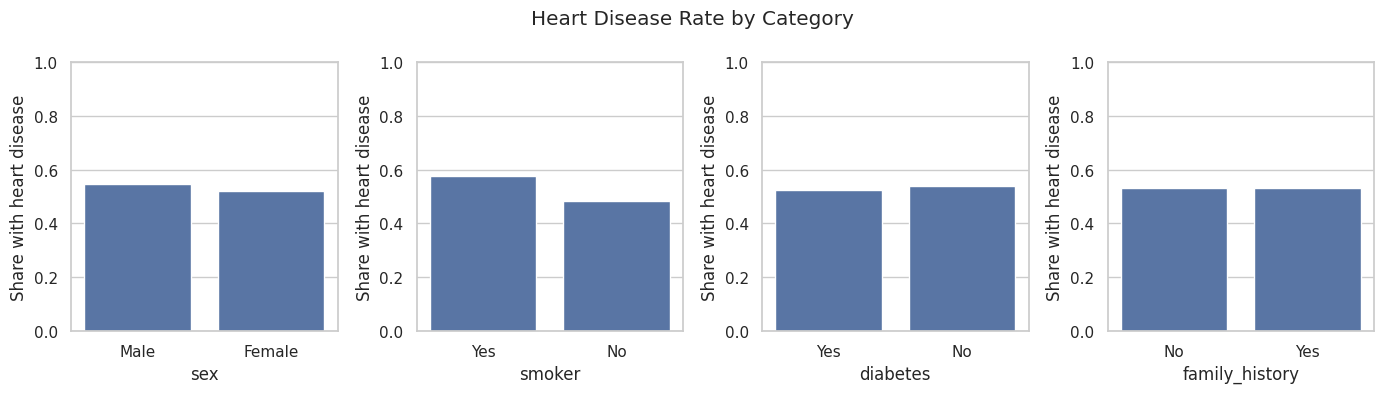

In [6]:
categories = ["sex", "smoker", "diabetes", "family_history"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, categories):
    sns.barplot(data=df, x=col, y="heart_disease", ax=ax, errorbar=None)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Share with heart disease")
plt.suptitle("Heart Disease Rate by Category")
plt.tight_layout()
plt.savefig("images/categorical_rates.png", dpi=300)
plt.show()

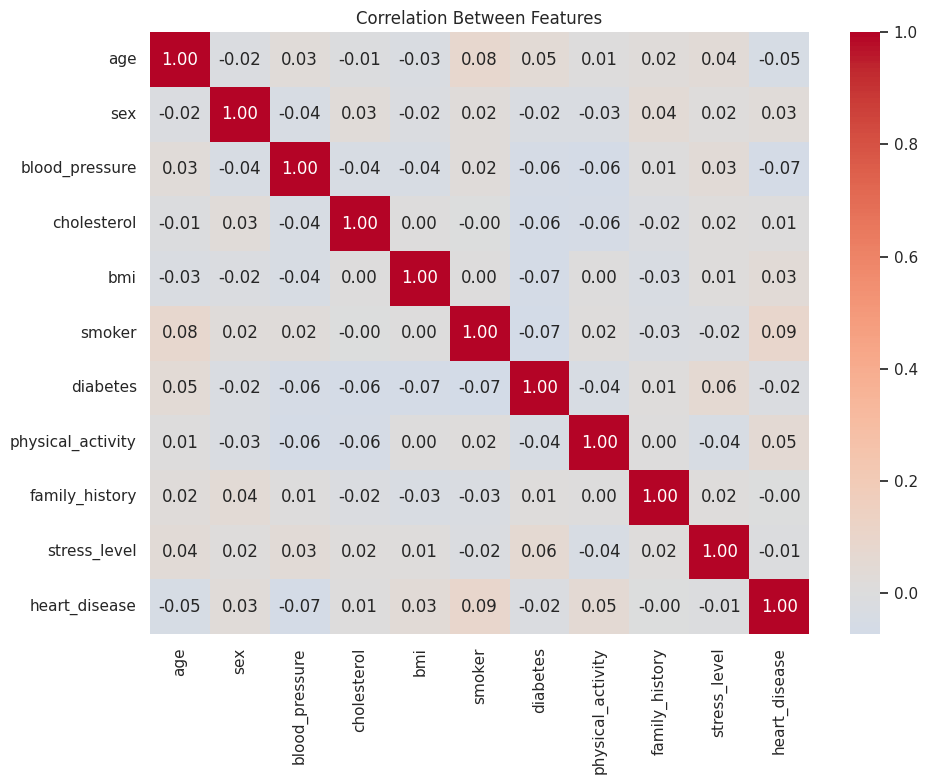

blood_pressure      -0.067
age                 -0.052
diabetes            -0.017
stress_level        -0.006
family_history      -0.001
cholesterol          0.009
sex                  0.028
bmi                  0.034
physical_activity    0.051
smoker               0.092
Name: heart_disease, dtype: float64


In [7]:
encoded = df.copy()
encoded["sex"] = encoded["sex"].map({"Female": 0, "Male": 1})
for col in ["smoker", "diabetes", "family_history"]:
    encoded[col] = encoded[col].map({"No": 0, "Yes": 1})

plt.figure(figsize=(10, 8))
sns.heatmap(encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.yticks(rotation=0)
plt.title("Correlation Between Features")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=300)
plt.show()

print(encoded.corr()["heart_disease"].drop("heart_disease").round(3).sort_values())

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = df.copy()
data["sex"] = data["sex"].map({"Female": 0, "Male": 1})
for col in ["smoker", "diabetes", "family_history"]:
    data[col] = data[col].map({"No": 0, "Yes": 1})

features = [c for c in data.columns if c != "heart_disease"]
X = data[features]
y = data["heart_disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Heart disease share (train, test):", round(y_train.mean(), 3), round(y_test.mean(), 3))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Training set: (400, 10)
Test set: (100, 10)
Heart disease share (train, test): 0.532 0.53


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    print(f"{name}: {accuracy_score(y_test, pred):.4f}")

print("Always predicting 'heart disease':", round(y_test.mean(), 4))

Logistic Regression: 0.5600
KNN (k=5): 0.4700
Decision Tree: 0.5300
Always predicting 'heart disease': 0.53


In [10]:
from sklearn.model_selection import cross_val_score

cv_scores = {
    name: cross_val_score(model, X_train_s, y_train, cv=5).mean()
    for name, model in models.items()
}
for name, score in cv_scores.items():
    print(f"{name}: {score:.4f}")

best_name = max(cv_scores, key=cv_scores.get)
best_model = models[best_name]
print("\nBest model:", best_name)

Logistic Regression: 0.5325
KNN (k=5): 0.5375
Decision Tree: 0.4975

Best model: KNN (k=5)


In [11]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)

y_pred = best_model.predict(X_test_s)

print(classification_report(y_test, y_pred))
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 score :", round(f1_score(y_test, y_pred), 4))

              precision    recall  f1-score   support

           0       0.42      0.36      0.39        47
           1       0.50      0.57      0.53        53

    accuracy                           0.47       100
   macro avg       0.46      0.46      0.46       100
weighted avg       0.46      0.47      0.47       100

Accuracy : 0.47
Precision: 0.5
Recall   : 0.566
F1 score : 0.531


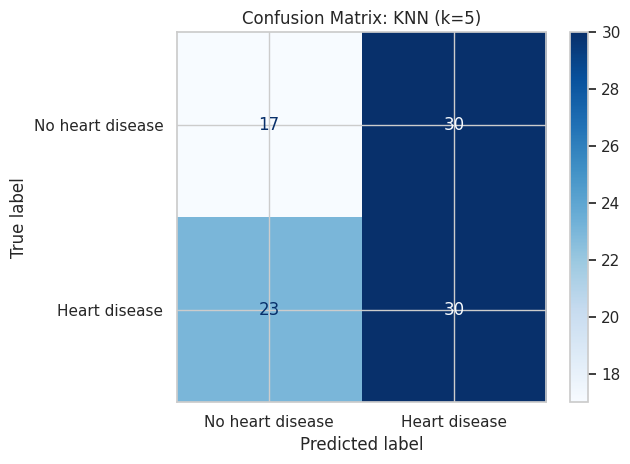

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=["No heart disease", "Heart disease"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=300)
plt.show()

In [13]:
import json

assert best_name == "KNN (k=5)", "Best model is not KNN - tell Claude before continuing"

report = classification_report(y_test, y_pred, output_dict=True)

model_data = {
    "model": "KNN",
    "k": 5,
    "features": features,
    "classes": [int(c) for c in best_model.classes_],
    "encoding": {
        "sex": {"Female": 0, "Male": 1},
        "smoker": {"No": 0, "Yes": 1},
        "diabetes": {"No": 0, "Yes": 1},
        "family_history": {"No": 0, "Yes": 1},
    },
    "ranges": {f: [float(X[f].min()), float(X[f].max())] for f in features},
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "X_train": X_train_s.round(5).tolist(),
    "y_train": [int(v) for v in y_train],
    "metrics": {
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred), 4),
        "recall": round(recall_score(y_test, y_pred), 4),
        "f1": round(f1_score(y_test, y_pred), 4),
        "confusion_matrix": cm.tolist(),
        "report": report,
    },
}

os.makedirs("model", exist_ok=True)
with open("model/heart_model.json", "w") as f:
    json.dump(model_data, f)

print("Saved. Training rows:", len(model_data["X_train"]))
print("Best model:", best_name)
print("Test accuracy:", model_data["metrics"]["accuracy"])

Saved. Training rows: 400
Best model: KNN (k=5)
Test accuracy: 0.47


In [14]:
import shutil
from google.colab import files

shutil.make_archive("images", "zip", "images")
files.download("model/heart_model.json")
files.download("images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>